# code_199 · Risk becomes an action only after specifying value

**Book:** section 37.4. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_37_GUIDE.md), [execution evidence](../CHAPTER_37_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_199).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Probability and interval contracts identify fitting and calibration roles, uncertainty sources, assessment units and decision costs. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7899;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7899


<a id="cost-capacity-and-policy-selection"></a>
 ## Separate event probability, action benefit and resource capacity
 Generate 120 independent days with 30 candidates: 60 source, 15 calibration, 10 policy-selection and 35 final. A source logistic model predicts a generated actionable finding from three features. A separate calibration logistic fit maps source-model logits to probabilities. A finding's assumed avoided loss B is between 5 and 20 utility units and inspection cost C between 1 and 5. Inspection is assumed to avert all of this event loss; this is a declared decision model, not an estimated causal effect. Expected incremental utility is pB−C, so the unconstrained candidate threshold is C/B and differs among sites. Each day has capacity ten, with equal resource cost per visit.

 Compare three frozen policies: choose up to ten positive-utility candidates in descending pB−C; choose the ten largest risks; or use a probability threshold selected from a fixed grid on the separate policy-selection days, retaining only the ten largest risks if needed. Source/calibration/policy days never enter final utility. The latter threshold is an empirical workflow choice, not a normative value inferred from final outcomes.


In [2]:
from sklearn.linear_model import LogisticRegression
days=120;perday=30;group=np.repeat(np.arange(days),perday);X=rng.normal(size=(days*perday,3));truth=expit(-1.5+1.5*X[:,0]-.6*X[:,1]+.3*X[:,2]);Y=rng.binomial(1,truth);benefit=rng.uniform(5,20,len(Y));cost=rng.uniform(1,5,len(Y));source=group<60;cal=(group>=60)&(group<75);selection=(group>=75)&(group<85);final=group>=85;model=LogisticRegression(C=1,max_iter=300).fit(X[source],Y[source]);calibrator=LogisticRegression(C=1e6,max_iter=300).fit(model.decision_function(X[cal])[:,None],Y[cal]);p=calibrator.predict_proba(model.decision_function(X)[:,None])[:,1];utility=p*benefit-cost
def choose(indices,kind,threshold=.2):
    action=np.zeros(len(indices),bool);days_here=group[indices]
    for d in np.unique(days_here):
        local=np.flatnonzero(days_here==d);global_ids=indices[local];score=utility[global_ids] if kind=='Utility' else p[global_ids];eligible=score>0 if kind=='Utility' else (p[global_ids]>=threshold if kind=='Threshold' else np.ones(len(local),bool));ids=local[eligible];action[ids[np.argsort(-score[eligible],kind='stable')[:10]]]=True
    return action
sel=np.flatnonzero(selection);grid=np.linspace(.05,.8,31);values=[np.mean(choose(sel,'Threshold',t)*(Y[sel]*benefit[sel]-cost[sel])) for t in grid];threshold=float(grid[np.argmax(values)]);idx=np.flatnonzero(final);actions={kind:choose(idx,kind,threshold) for kind in ['Utility','Risk top10','Threshold']};rows={}
for kind,action in actions.items():
    realized=action*(Y[idx]*benefit[idx]-cost[idx]);expected=action*(truth[idx]*benefit[idx]-cost[idx]);count=action.reshape(35,30).sum(1);rows[kind]={'realized_utility_per_day':float(realized.sum()/35),'simulator_expected_utility_per_day':float(expected.sum()/35),'inspections_per_day':float(count.mean()),'daily_capacity_max_used':int(count.max()),'daily_realized_utility':realized.reshape(35,30).sum(1).tolist()};assert count.max()<=10
assert len(idx)==1050 and selection.sum()==300;assert not set(group[selection])&set(group[final]);RESULTS.update(day_roles=[60,15,10,35],candidates_per_day=30,capacity_each_day=10,selected_probability_threshold=threshold,assumed_full_avoided_loss_not_estimated_effect=True,policy_scores=rows);display(pd.DataFrame([{k:v for k,v in r.items() if k!='daily_realized_utility'} for r in rows.values()],index=list(rows)))


,realized_utility_per_day,simulator_expected_utility_per_day,inspections_per_day,daily_capacity_max_used
Utility,37.308946,39.927453,9.942857,10
Risk top10,33.147185,35.645671,10.000000,10
Threshold,33.147185,35.645671,10.000000,10


<a id="decision-curves-and-service-constraint"></a>
 ## Make the exchange rate and capacity visible
 A conventional binary decision curve computes TP/n−FP/n×t/(1−t) for a stated risk threshold t, comparing with inspect-none and inspect-all. This summarizes a homogeneous false-positive exchange rate; it is not the heterogeneous B/C capacity allocation above and does not prove treatment efficacy. Show the full predeclared final curve descriptively, without using it to select the reported policy. Visual B2 plots the first fixed final day's expected net utilities, ordered before outcomes, with the up-to-ten admitted candidates marked. Positive expected value and capacity are two separate admission conditions. Realized utility remains noisy, so report all 35 final days rather than cherry-picking the illustrated day.


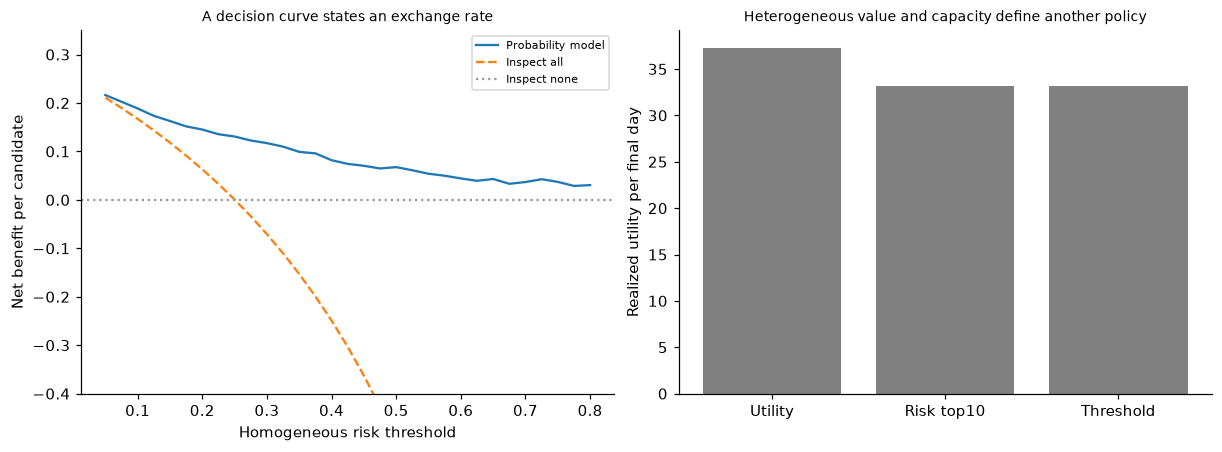

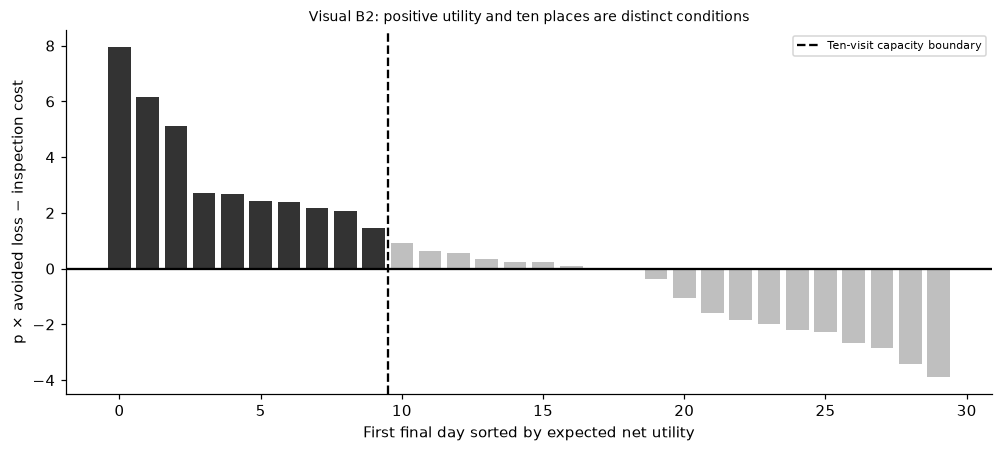

In [3]:
thresholds=np.linspace(.05,.8,31);net=[];all_net=[]
for t in thresholds:
    action=p[idx]>=t;tp=np.sum(action&(Y[idx]==1));fp=np.sum(action&(Y[idx]==0));net.append(float(tp/1050-fp/1050*t/(1-t)));all_net.append(float(Y[idx].mean()-(1-Y[idx].mean())*t/(1-t)))
day0=idx[:30];order=np.argsort(-utility[day0],kind='stable');admitted=actions['Utility'][:30][order];assert admitted.sum()<=10;assert np.all(utility[day0][order][admitted]>0);RESULTS.update(decision_curve_thresholds=thresholds.tolist(),decision_curve_model=net,decision_curve_all=all_net,decision_curve_is_descriptive_not_policy_selection=True,first_final_day=85,first_day_expected_net_utility_sorted=utility[day0][order].tolist(),first_day_admitted_sorted=admitted.tolist());fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(thresholds,net,label='Probability model');axes[0].plot(thresholds,all_net,'--',label='Inspect all');axes[0].axhline(0,color='.6',linestyle=':',label='Inspect none');axes[0].set(xlabel='Homogeneous risk threshold',ylabel='Net benefit per candidate',ylim=(-.4,.35),title='A decision curve states an exchange rate');axes[0].legend(fontsize=7);xx=np.arange(3);axes[1].bar(xx,[rows[k]['realized_utility_per_day'] for k in rows],color='.5');axes[1].set(xticks=xx,xticklabels=['Utility','Risk top10','Threshold'],ylabel='Realized utility per final day',title='Heterogeneous value and capacity define another policy');plt.show();fig,ax=plt.subplots(figsize=(9,4));ax.bar(np.arange(30),utility[day0][order],color=np.where(admitted,'.2','.75'));ax.axhline(0,color='black');ax.axvline(9.5,color='black',linestyle='--',label='Ten-visit capacity boundary');ax.set(xlabel='First final day sorted by expected net utility',ylabel='p × avoided loss − inspection cost',title='Visual B2: positive utility and ten places are distinct conditions');ax.legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_199','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['source logistic model with separate probability calibration and policy selection', 'heterogeneous avoided-loss utility and daily capacity ten allocation', 'actual decision-curve net benefit with declared threshold exchange rates', 'realized final utility versus simulator expected utility audit'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["source logistic model with separate probability calibration and policy selection", "heterogeneous avoided-loss utility and daily capacity ten allocation", "actual decision-curve net benefit with declared threshold exchange rates", "realized final utility versus simulator expected utility audit"], "elapsed_seconds": 0.292, "example_id": "code_199", "hardware": "Darwin arm64 CPU", "results": {"assumed_full_avoided_loss_not_estimated_effect": true, "candidates_per_day": 30, "capacity_each_day": 10, "day_roles": [60, 15, 10, 35], "decision_curve_all": [0.21102756892230576, 0.1897039897039897, 0.16719576719576718, 0.14340136054421768, 0.11820728291316523, 0.09148629148629148, 0.0630952380952381, 0.03287250384024573, 0.0006349206349206271, -0.03382594417077178, -0.07074829931972793, -0.11040564373897704, -0.15311355311355324, -0.19923809523809516, -0.2492063492063492, -0.3035196687370601, -0.3627705627705628, -0.42766439909297066, -0.4990476